In [1]:
"hi"

'hi'

In [2]:
from sklearn.tree import DecisionTreeClassifier
dt_model = DecisionTreeClassifier(criterion="entropy",)

In [3]:
import pandas as pd
dfship = pd.read_csv(r"C:\Users\DELL\Downloads\Titanic dataset.csv")
dfship

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [4]:
dfship.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')

In [5]:
col = ['PassengerId', 'Name', 'Ticket', 'Fare', 'Cabin']

In [6]:
dfship.drop(col,axis=1,inplace=True)
dfship

,Survived,Pclass,Sex,Age,SibSp,Parch,Embarked
0,0,3,male,22.0,1,0,S
1,1,1,female,38.0,1,0,C
2,1,3,female,26.0,0,0,S
3,1,1,female,35.0,1,0,S
4,0,3,male,35.0,0,0,S
...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,S
887,1,1,female,19.0,0,0,S
888,0,3,female,NaN,1,2,S
889,1,1,male,26.0,0,0,C


In [7]:
dfship["family"] = dfship["SibSp"]+dfship["Parch"]
col = ["SibSp","Parch"]
# dfship.drop(col,axis=1,inplace=True)
dfship

,Survived,Pclass,Sex,Age,SibSp,Parch,Embarked,family
0,0,3,male,22.0,1,0,S,1
1,1,1,female,38.0,1,0,C,1
2,1,3,female,26.0,0,0,S,0
3,1,1,female,35.0,1,0,S,1
4,0,3,male,35.0,0,0,S,0
...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,S,0
887,1,1,female,19.0,0,0,S,0
888,0,3,female,NaN,1,2,S,3
889,1,1,male,26.0,0,0,C,0


In [8]:
dfship.isna().sum()

Survived      0
Pclass        0
Sex           0
Age         177
SibSp         0
Parch         0
Embarked      2
family        0
dtype: int64

In [9]:
dfship.dtypes

Survived      int64
Pclass        int64
Sex          object
Age         float64
SibSp         int64
Parch         int64
Embarked     object
family        int64
dtype: object

In [10]:
dfship["Age"].mean().round()

np.float64(30.0)

In [11]:
dfship["Age"].fillna(dfship["Age"].mean().round()).isna().sum()
dfship["Age"]=dfship["Age"].fillna(dfship["Age"].mean().round())
dfship.isna().sum()



Survived    0
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Embarked    2
family      0
dtype: int64

In [12]:
dfship.dropna(inplace=True)
dfship.isna().sum()

Survived    0
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Embarked    0
family      0
dtype: int64

### eror detect

In [13]:
dfship

,Survived,Pclass,Sex,Age,SibSp,Parch,Embarked,family
0,0,3,male,22.0,1,0,S,1
1,1,1,female,38.0,1,0,C,1
2,1,3,female,26.0,0,0,S,0
3,1,1,female,35.0,1,0,S,1
4,0,3,male,35.0,0,0,S,0
...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,S,0
887,1,1,female,19.0,0,0,S,0
888,0,3,female,30.0,1,2,S,3
889,1,1,male,26.0,0,0,C,0


<Axes: >

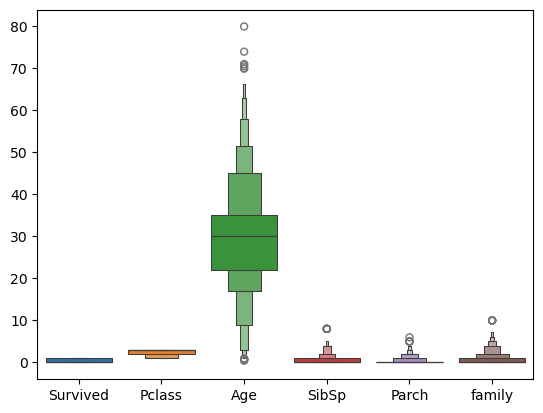

In [14]:
import seaborn as sns
sns.boxenplot(dfship)

<Axes: ylabel='family'>

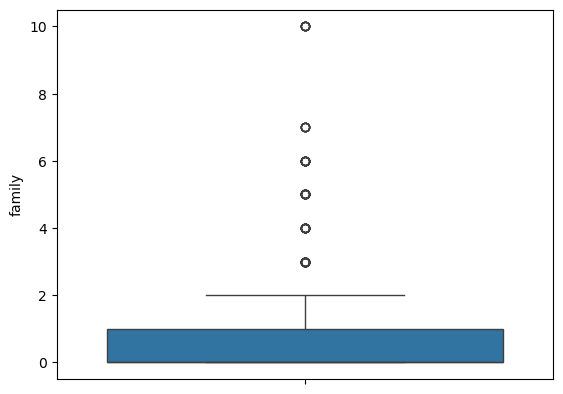

In [15]:
sns.boxplot(dfship["family"])

In [16]:
# IQR
cols = ["Age","family"]
for c in cols:
    q1 = dfship[c].quantile(0.25)
    q3 = dfship[c].quantile(0.75)
    iqr = q3-q1
    lower = q1-(1.5*iqr)
    upper = q3+(1.5*iqr)
    dfship[c]=dfship[c].map(lambda x: lower if x<lower else upper if x>upper else x )

    


<Axes: >

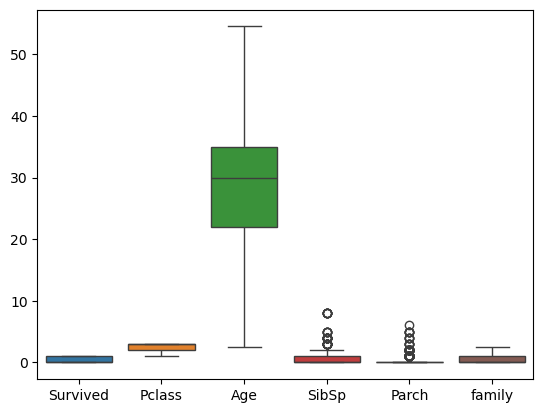

In [17]:
sns.boxplot(dfship)

## Encoding

In [18]:
dfship.dtypes

Survived      int64
Pclass        int64
Sex          object
Age         float64
SibSp         int64
Parch         int64
Embarked     object
family      float64
dtype: object

In [19]:
dfship["Sex"].unique()

array(['male', 'female'], dtype=object)

In [20]:
dfship["Embarked"].unique()

array(['S', 'C', 'Q'], dtype=object)

In [21]:
dfship=pd.get_dummies(dfship,dtype=int)
dfship

,Survived,Pclass,Age,SibSp,Parch,family,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
0,0,3,22.0,1,0,1.0,0,1,0,0,1
1,1,1,38.0,1,0,1.0,1,0,1,0,0
2,1,3,26.0,0,0,0.0,1,0,0,0,1
3,1,1,35.0,1,0,1.0,1,0,0,0,1
4,0,3,35.0,0,0,0.0,0,1,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,27.0,0,0,0.0,0,1,0,0,1
887,1,1,19.0,0,0,0.0,1,0,0,0,1
888,0,3,30.0,1,2,2.5,1,0,0,0,1
889,1,1,26.0,0,0,0.0,0,1,1,0,0


In [22]:
x = dfship.drop("Survived",axis=1)
x

,Pclass,Age,SibSp,Parch,family,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
0,3,22.0,1,0,1.0,0,1,0,0,1
1,1,38.0,1,0,1.0,1,0,1,0,0
2,3,26.0,0,0,0.0,1,0,0,0,1
3,1,35.0,1,0,1.0,1,0,0,0,1
4,3,35.0,0,0,0.0,0,1,0,0,1
...,...,...,...,...,...,...,...,...,...,...
886,2,27.0,0,0,0.0,0,1,0,0,1
887,1,19.0,0,0,0.0,1,0,0,0,1
888,3,30.0,1,2,2.5,1,0,0,0,1
889,1,26.0,0,0,0.0,0,1,1,0,0


In [23]:
y = dfship["Survived"]
y

0      0
1      1
2      1
3      1
4      0
      ..
886    0
887    1
888    0
889    1
890    0
Name: Survived, Length: 889, dtype: int64

In [24]:
y.value_counts()

Survived
0    549
1    340
Name: count, dtype: int64

In [25]:
from imblearn.over_sampling import RandomOverSampler
ros = RandomOverSampler()
ros

,sampling_strategy,'auto'
,random_state,None
,shrinkage,None


In [26]:
xros,yros=ros.fit_resample(x,y)


In [27]:
xros.shape

(1098, 10)

In [28]:
yros.shape

(1098,)

In [29]:
yros.value_counts()

Survived
0    549
1    549
Name: count, dtype: int64

<Axes: xlabel='Survived'>

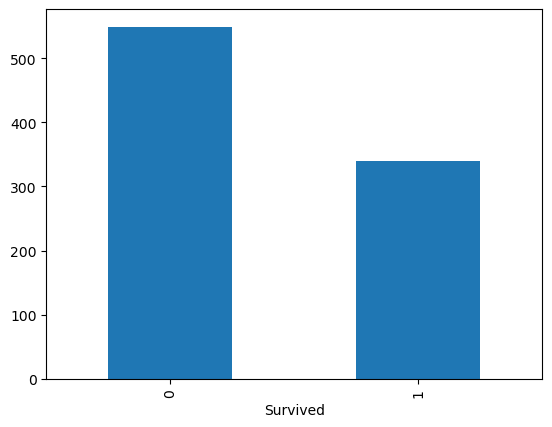

In [30]:
import matplotlib.pyplot as plt
y.value_counts().plot(kind="bar")

In [31]:
from sklearn.model_selection import train_test_split
xtrain,xtest,ytrain,ytest = train_test_split(xros,yros,test_size=0.2,random_state=2)


### Decision tree

In [32]:
from sklearn.tree import DecisionTreeClassifier
dt_model = DecisionTreeClassifier()

In [33]:
dt_model.fit(xtrain,ytrain)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [34]:
dt_model.score(xtest,ytest)

0.8227272727272728

### cross validation

In [35]:
from sklearn.model_selection import KFold,cross_val_score
import numpy as np
data=np.arange(100,150,5)
kf = KFold(n_splits=3)
list(kf.split(data))



[(array([4, 5, 6, 7, 8, 9]), array([0, 1, 2, 3])),
 (array([0, 1, 2, 3, 7, 8, 9]), array([4, 5, 6])),
 (array([0, 1, 2, 3, 4, 5, 6]), array([7, 8, 9]))]

In [36]:
from sklearn.model_selection import LeaveOneOut
loocv = LeaveOneOut()
list(loocv.split(data))

[(array([1, 2, 3, 4, 5, 6, 7, 8, 9]), array([0])),
 (array([0, 2, 3, 4, 5, 6, 7, 8, 9]), array([1])),
 (array([0, 1, 3, 4, 5, 6, 7, 8, 9]), array([2])),
 (array([0, 1, 2, 4, 5, 6, 7, 8, 9]), array([3])),
 (array([0, 1, 2, 3, 5, 6, 7, 8, 9]), array([4])),
 (array([0, 1, 2, 3, 4, 6, 7, 8, 9]), array([5])),
 (array([0, 1, 2, 3, 4, 5, 7, 8, 9]), array([6])),
 (array([0, 1, 2, 3, 4, 5, 6, 8, 9]), array([7])),
 (array([0, 1, 2, 3, 4, 5, 6, 7, 9]), array([8])),
 (array([0, 1, 2, 3, 4, 5, 6, 7, 8]), array([9]))]

In [37]:
from sklearn.model_selection import LeavePOut
lpocv=LeavePOut(3)
# LeaveOneOut(p=2)
list(lpocv.split(data))

[(array([3, 4, 5, 6, 7, 8, 9]), array([0, 1, 2])),
 (array([2, 4, 5, 6, 7, 8, 9]), array([0, 1, 3])),
 (array([2, 3, 5, 6, 7, 8, 9]), array([0, 1, 4])),
 (array([2, 3, 4, 6, 7, 8, 9]), array([0, 1, 5])),
 (array([2, 3, 4, 5, 7, 8, 9]), array([0, 1, 6])),
 (array([2, 3, 4, 5, 6, 8, 9]), array([0, 1, 7])),
 (array([2, 3, 4, 5, 6, 7, 9]), array([0, 1, 8])),
 (array([2, 3, 4, 5, 6, 7, 8]), array([0, 1, 9])),
 (array([1, 4, 5, 6, 7, 8, 9]), array([0, 2, 3])),
 (array([1, 3, 5, 6, 7, 8, 9]), array([0, 2, 4])),
 (array([1, 3, 4, 6, 7, 8, 9]), array([0, 2, 5])),
 (array([1, 3, 4, 5, 7, 8, 9]), array([0, 2, 6])),
 (array([1, 3, 4, 5, 6, 8, 9]), array([0, 2, 7])),
 (array([1, 3, 4, 5, 6, 7, 9]), array([0, 2, 8])),
 (array([1, 3, 4, 5, 6, 7, 8]), array([0, 2, 9])),
 (array([1, 2, 5, 6, 7, 8, 9]), array([0, 3, 4])),
 (array([1, 2, 4, 6, 7, 8, 9]), array([0, 3, 5])),
 (array([1, 2, 4, 5, 7, 8, 9]), array([0, 3, 6])),
 (array([1, 2, 4, 5, 6, 8, 9]), array([0, 3, 7])),
 (array([1, 2, 4, 5, 6, 7, 9]),

In [38]:
kf = KFold(n_splits=10)


In [39]:
dt1 = DecisionTreeClassifier()

In [40]:
sc = cross_val_score(dt1,x,y,cv=kf,n_jobs=-1)

In [41]:
sc
sc.mean()

np.float64(0.7817671092951992)

In [42]:
dt2 = DecisionTreeClassifier()

In [43]:
from sklearn.model_selection import StratifiedKFold
kf2 = StratifiedKFold(n_splits=15)
sc1  = cross_val_score(dt2 ,x,y,cv=kf2,n_jobs=-1)

In [44]:
from sklearn.model_selection import cross_val_score
dt1 = DecisionTreeClassifier()
scores = cross_val_score(dt1,xros,yros,cv=20,n_jobs=-1)


In [45]:
scores
scores.mean()

np.float64(0.8443097643097642)

### Cross validation with xtrain y train

In [46]:
dt2 = DecisionTreeClassifier()
sc = cross_val_score(dt2,xtrain,ytrain,cv=20,n_jobs=-1)


In [47]:
sc.mean()

np.float64(0.8223572938689218)

## hyperparameter tuining

In [48]:
from sklearn.model_selection import GridSearchCV

In [49]:
params = {
    "criterion":["gini","entropy","log_loss"],
    "splitter":["best","random"],
    "max_depth":[5,7,9,10]
}


In [50]:
dt3 = DecisionTreeClassifier()
gscv = GridSearchCV(estimator=dt3,param_grid=params,cv=10,n_jobs=-1)
gscv

,estimator,DecisionTreeClassifier()
,param_grid,"{'criterion': ['gini', 'entropy', ...], 'max_depth': [5, 7, ...], 'splitter': ['best', 'random']}"
,scoring,None
,n_jobs,-1
,refit,True
,cv,10
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,criterion,'gini'


In [51]:
gscv.fit(xros,yros)

,estimator,DecisionTreeClassifier()
,param_grid,"{'criterion': ['gini', 'entropy', ...], 'max_depth': [5, 7, ...], 'splitter': ['best', 'random']}"
,scoring,None
,n_jobs,-1
,refit,True
,cv,10
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,criterion,'gini'


In [52]:
gscv.cv_results_

{'mean_fit_time': array([0.01294966, 0.01385009, 0.01460819, 0.01443405, 0.01303885,
        0.01186798, 0.01325831, 0.01062684, 0.01166959, 0.01070504,
        0.01164417, 0.01034956, 0.01241586, 0.0100513 , 0.01301017,
        0.0125139 , 0.01303639, 0.0118962 , 0.0124193 , 0.01071274,
        0.01251605, 0.00954039, 0.01238933, 0.01062326]),
 'std_fit_time': array([0.00231645, 0.00178723, 0.00484115, 0.00425339, 0.0016077 ,
        0.00178492, 0.00202406, 0.00110569, 0.00298271, 0.00307808,
        0.00161738, 0.00191888, 0.00124371, 0.00133645, 0.00232896,
        0.00458534, 0.0029532 , 0.00673988, 0.00170483, 0.00224695,
        0.00207184, 0.00067252, 0.00246646, 0.00345442]),
 'mean_score_time': array([0.00716794, 0.00884314, 0.00925999, 0.00836172, 0.00612056,
        0.0064126 , 0.00770376, 0.00774753, 0.00666757, 0.00574839,
        0.00552073, 0.00577719, 0.00587986, 0.00683796, 0.00596898,
        0.00724432, 0.00691698, 0.00789609, 0.00602188, 0.00756981,
        0.007865

In [53]:
pd.DataFrame(gscv.cv_results_)

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_criterion,param_max_depth,param_splitter,params,split0_test_score,split1_test_score,...,split3_test_score,split4_test_score,split5_test_score,split6_test_score,split7_test_score,split8_test_score,split9_test_score,mean_test_score,std_test_score,rank_test_score
0,0.012950,0.002316,0.007168,0.001120,gini,5,best,"{'criterion': 'gini', 'max_depth': 5, 'splitte...",0.781818,0.763636,...,0.809091,0.736364,0.827273,0.800000,0.827273,0.816514,0.862385,0.809708,0.039729,16
1,0.013850,0.001787,0.008843,0.002481,gini,5,random,"{'criterion': 'gini', 'max_depth': 5, 'splitte...",0.763636,0.727273,...,0.754545,0.718182,0.800000,0.827273,0.863636,0.788991,0.834862,0.793294,0.049018,24
2,0.014608,0.004841,0.009260,0.005838,gini,7,best,"{'criterion': 'gini', 'max_depth': 7, 'splitte...",0.772727,0.763636,...,0.809091,0.736364,0.827273,0.790909,0.845455,0.816514,0.871560,0.809716,0.041940,15
3,0.014434,0.004253,0.008362,0.003018,gini,7,random,"{'criterion': 'gini', 'max_depth': 7, 'splitte...",0.754545,0.763636,...,0.763636,0.754545,0.836364,0.836364,0.881818,0.807339,0.880734,0.816080,0.051765,10
4,0.013039,0.001608,0.006121,0.000519,gini,9,best,"{'criterion': 'gini', 'max_depth': 9, 'splitte...",0.745455,0.772727,...,0.800000,0.809091,0.818182,0.854545,0.854545,0.853211,0.862385,0.825196,0.041415,4
5,0.011868,0.001785,0.006413,0.001707,gini,9,random,"{'criterion': 'gini', 'max_depth': 9, 'splitte...",0.745455,0.763636,...,0.781818,0.745455,0.845455,0.818182,0.927273,0.816514,0.862385,0.819708,0.058943,8
6,0.013258,0.002024,0.007704,0.002833,gini,10,best,"{'criterion': 'gini', 'max_depth': 10, 'splitt...",0.754545,0.763636,...,0.809091,0.790909,0.818182,0.881818,0.872727,0.862385,0.862385,0.830659,0.047451,1
7,0.010627,0.001106,0.007748,0.005100,gini,10,random,"{'criterion': 'gini', 'max_depth': 10, 'splitt...",0.718182,0.754545,...,0.772727,0.781818,0.809091,0.818182,0.872727,0.844037,0.825688,0.807882,0.049203,17
8,0.011670,0.002983,0.006668,0.001181,entropy,5,best,"{'criterion': 'entropy', 'max_depth': 5, 'spli...",0.790909,0.763636,...,0.763636,0.736364,0.818182,0.800000,0.827273,0.807339,0.862385,0.804245,0.041117,19
9,0.010705,0.003078,0.005748,0.000808,entropy,5,random,"{'criterion': 'entropy', 'max_depth': 5, 'spli...",0.754545,0.754545,...,0.763636,0.745455,0.809091,0.818182,0.845455,0.761468,0.825688,0.795079,0.042545,23


In [54]:
gscv.best_score_

np.float64(0.8306588824020016)

In [55]:
gscv.best_params_

{'criterion': 'gini', 'max_depth': 10, 'splitter': 'best'}

## hyperparameters tuning 2nd method

In [56]:
from sklearn.model_selection import RandomizedSearchCV
params

{'criterion': ['gini', 'entropy', 'log_loss'],
 'splitter': ['best', 'random'],
 'max_depth': [5, 7, 9, 10]}

In [57]:
dt4 = DecisionTreeClassifier()

In [58]:
rscv = RandomizedSearchCV(estimator=dt4,param_distributions=params,n_iter=10,cv=10,n_jobs=-1)

In [59]:

rscv

,estimator,DecisionTreeClassifier()
,param_distributions,"{'criterion': ['gini', 'entropy', ...], 'max_depth': [5, 7, ...], 'splitter': ['best', 'random']}"
,n_iter,10
,scoring,None
,n_jobs,-1
,refit,True
,cv,10
,verbose,0
,pre_dispatch,'2*n_jobs'
,random_state,None
,error_score,nan


In [60]:
rscv.fit(xros,yros)

,estimator,DecisionTreeClassifier()
,param_distributions,"{'criterion': ['gini', 'entropy', ...], 'max_depth': [5, 7, ...], 'splitter': ['best', 'random']}"
,n_iter,10
,scoring,None
,n_jobs,-1
,refit,True
,cv,10
,verbose,0
,pre_dispatch,'2*n_jobs'
,random_state,None
,error_score,nan


In [61]:
rscv.cv_results_

{'mean_fit_time': array([0.01121075, 0.01054442, 0.01108038, 0.0121918 , 0.0234875 ,
        0.01974251, 0.01469851, 0.01396999, 0.01488016, 0.01309602]),
 'std_fit_time': array([0.0012184 , 0.00075087, 0.00095013, 0.00340323, 0.01171543,
        0.00725031, 0.00457282, 0.00434729, 0.00261971, 0.00279452]),
 'mean_score_time': array([0.00586824, 0.00693469, 0.00916152, 0.00712576, 0.00754023,
        0.01690319, 0.01015146, 0.00954392, 0.01663945, 0.00749948]),
 'std_score_time': array([0.00087573, 0.00356911, 0.00978962, 0.00107531, 0.00145016,
        0.01616296, 0.00778627, 0.00627902, 0.01316955, 0.00289086]),
 'param_splitter': masked_array(data=['best', 'random', 'random', 'best', 'best', 'best',
                    'random', 'random', 'random', 'random'],
              mask=[False, False, False, False, False, False, False, False,
                    False, False],
        fill_value=np.str_('?'),
             dtype=object),
 'param_max_depth': masked_array(data=[9, 5, 10, 5, 7, 

In [62]:
rscv.best_score_

np.float64(0.8279149291075896)

In [63]:
rscv.best_params_

{'splitter': 'best', 'max_depth': 10, 'criterion': 'entropy'}

## automl

In [64]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.ensemble import AdaBoostClassifier
from sklearn.neighbors import KNeighborsClassifier


In [65]:
dt1 = DecisionTreeClassifier()
lr1 = LogisticRegression()
rfc1 = RandomForestClassifier()
svm = SVC()
adb = AdaBoostClassifier()
knn = KNeighborsClassifier()



In [66]:
lst_mod = [dt1,lr1,rfc1,svm,adb,knn]

In [67]:
import time

In [68]:
for m in lst_mod:
    scores = cross_val_score(m,xros,yros,cv=20,n_jobs=-1)
    print(m," ",scores.mean())
    time.sleep(2)
    


DecisionTreeClassifier()   0.8424915824915825
LogisticRegression()   0.7924242424242424
RandomForestClassifier()   0.8452693602693602
SVC()   0.7650505050505051
AdaBoostClassifier()   0.7887710437710437
KNeighborsClassifier()   0.8143097643097642
